# 관측 타임라인과 구간 탐색

실제 V3 원본 인덱스와 집계만 사용합니다. 원본·V1/V2는 읽기 전용입니다. 대시보드는 `dashboard/app.py`로 실행합니다.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.common import TABLES, CFG
from src.detail import get_detail
from src.visuals import detail_figure
assert Path(sys.executable).resolve() == Path(CFG['python']).resolve()
print('실제 실행 Python:', sys.executable)
print('시간: raw / 연구 진단용 / 모델 학습 없음')


실제 실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
시간: raw / 연구 진단용 / 모델 학습 없음


In [2]:
tool = '01M01'
segments = pd.read_parquet(TABLES/'time_segment_summary.parquet')
display(segments[segments.Tool.eq(tool) & segments.kind.eq('fixed')].head(20))

,start,end,sensor_observations,raw_rows,max_gap,process_changes,conflicts,null_low,null_high,null_leak,...,kind,segment_id,ttf_null_ratio_low,ttf_null_ratio_high,ttf_null_ratio_leak,density,fault_count,fault_near,has_gap,states
0,3283106,3299999,1579,1579,2188.0,45,0,0,0,0,...,fixed,-1,0.0,0.0,0.0,0.373794,0,False,True,OBSERVED|SPARSE|GAP
1,3300000,3399999,8919,8919,10976.0,321,0,0,0,0,...,fixed,-1,0.0,0.0,0.0,0.356749,0,False,True,OBSERVED|SPARSE|GAP
2,3400000,3499999,9463,9463,16476.0,153,0,0,0,0,...,fixed,-1,0.0,0.0,0.0,0.378509,0,False,True,OBSERVED|SPARSE|GAP
3,3500000,3599999,5133,5133,29760.0,134,0,0,0,0,...,fixed,-1,0.0,0.0,0.0,0.205314,0,False,True,OBSERVED|SPARSE|GAP
4,3600000,3699999,6371,6371,27864.0,151,0,0,0,0,...,fixed,-1,0.0,0.0,0.0,0.254832,0,False,True,OBSERVED|SPARSE|GAP
5,3700000,3799999,3087,3087,50924.0,99,0,0,0,0,...,fixed,-1,0.0,0.0,0.0,0.123476,0,False,True,OBSERVED|SPARSE|GAP
6,3800000,3899999,7823,7824,19124.0,252,0,0,0,0,...,fixed,-1,0.0,0.0,0.0,0.312911,0,False,True,OBSERVED|SPARSE|GAP
7,3900000,3999999,8064,8069,14076.0,216,0,0,0,0,...,fixed,-1,0.0,0.0,0.0,0.322550,0,False,True,OBSERVED|SPARSE|GAP
8,4000000,4099999,7799,7800,7472.0,272,0,0,0,0,...,fixed,-1,0.0,0.0,0.0,0.311951,0,False,True,OBSERVED|SPARSE|GAP
9,4100000,4199999,13877,13880,21156.0,384,0,0,0,0,...,fixed,-1,0.0,0.0,0.0,0.555063,0,False,True,OBSERVED|SPARSE|GAP


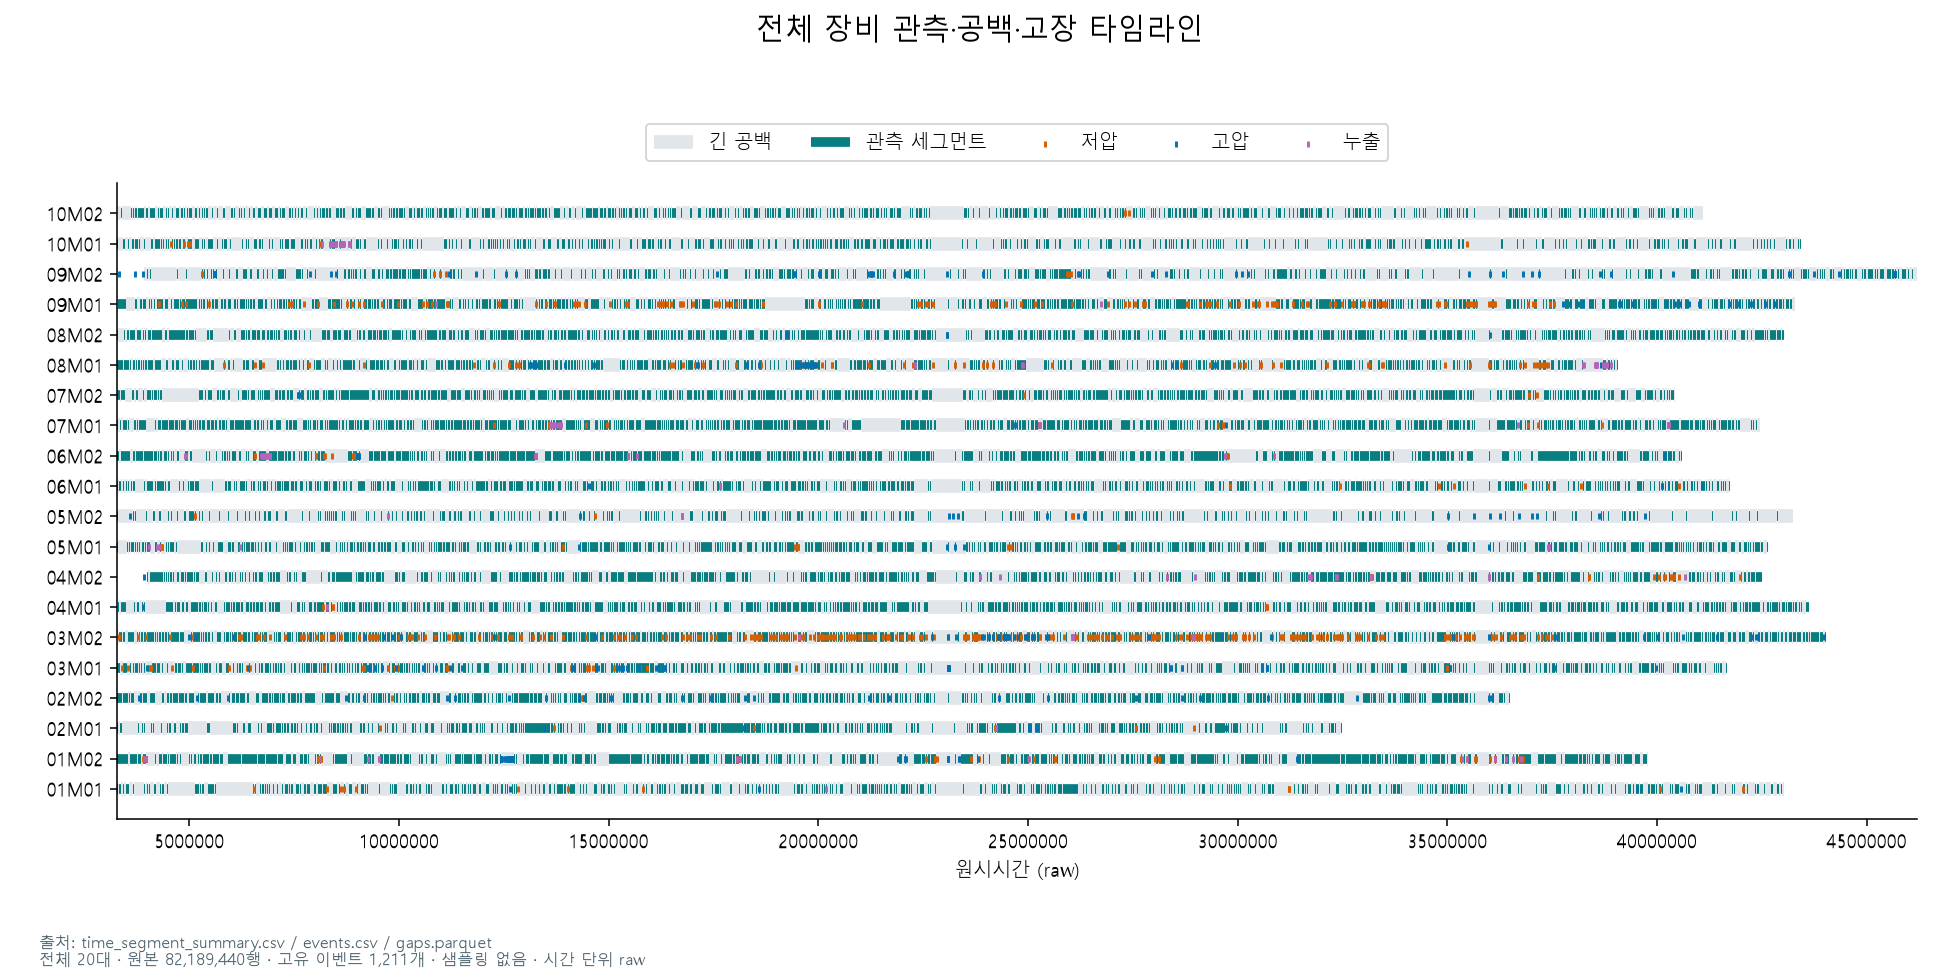

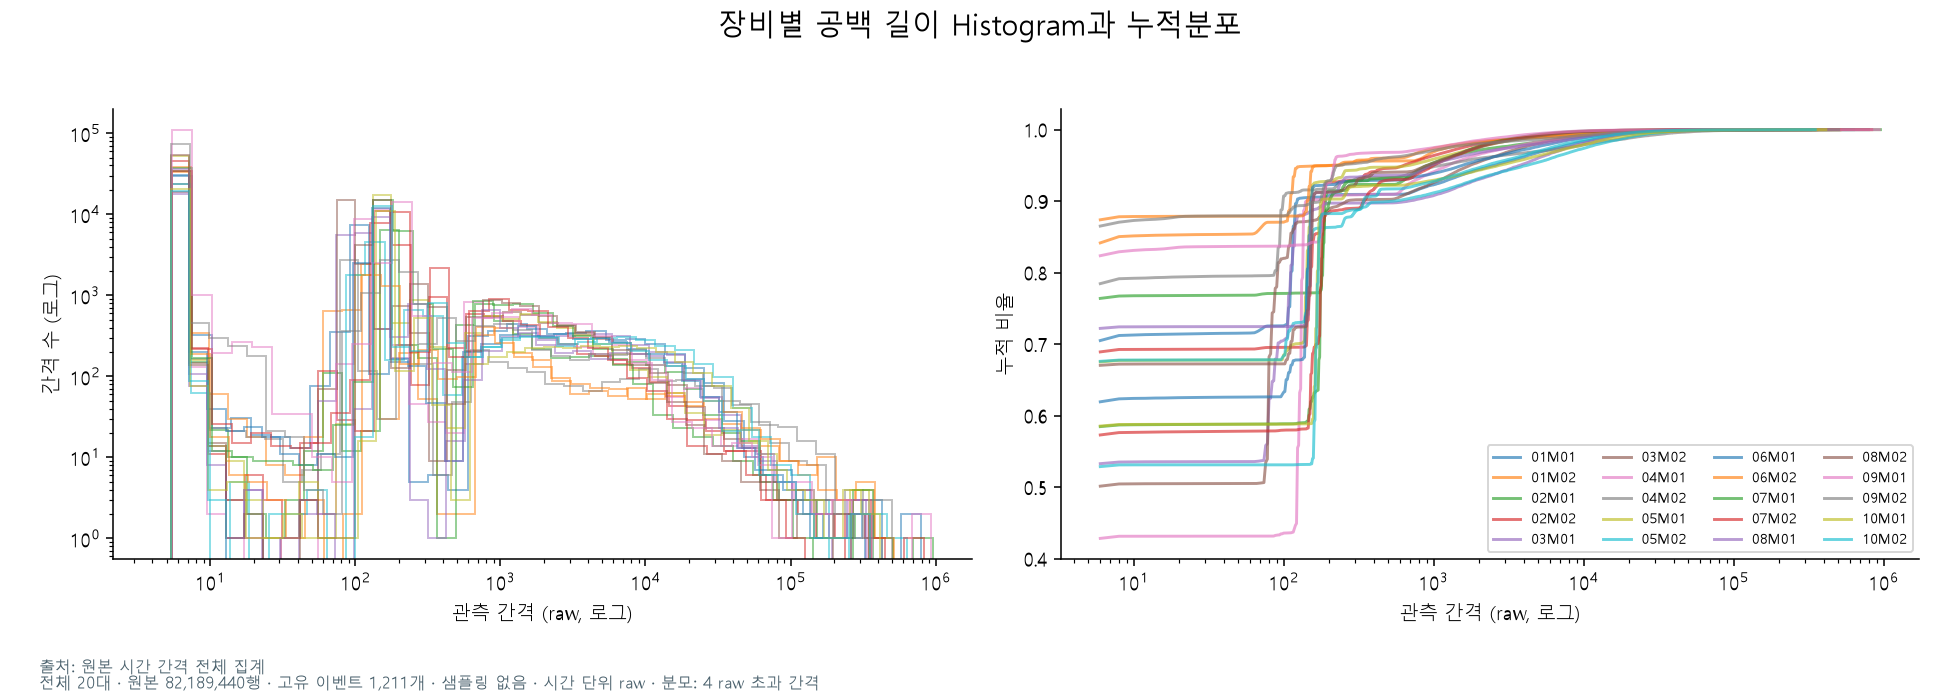

In [3]:
display(Image(filename=str(ROOT/'outputs/figures/timeline/all_tools.png')))
display(Image(filename=str(ROOT/'outputs/figures/timeline/gap_distribution.png')))

In [4]:
# 이 값들을 바꾸어 다른 실제 구간을 조회합니다. 최대20,000 raw입니다.
cases = json.loads((ROOT/'outputs/case_catalog.json').read_text(encoding='utf-8'))
case = next(c for c in cases if c['Tool']==tool and c['category']=='긴 센서 공백')
detail = get_detail(tool, case['start'], case['end'])
display(pd.DataFrame(detail['gaps']))
display(pd.DataFrame(detail['anchor_table']).head(15))
print(detail['load_audit'])

,Tool,start,end,gap_raw,long_gap
0,01M01,5631444,6425924,794480,True
1,01M01,6426656,6426764,108,True


,time,last_observation,current_lag,n_60,n_300,n_900,coverage_60,coverage_300,coverage_900,A_available,...,recipe_step,low,low_evidence,high,high_evidence,leak,leak_evidence,any,any_evidence,candidate_reason
0,6424140,5631444.0,792696.0,0,0,0,0.0,0.0,0.0,False,...,11.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,현재값 없음/12 raw 초과/공정충돌
1,6424200,5631444.0,792756.0,0,0,0,0.0,0.0,0.0,False,...,11.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,현재값 없음/12 raw 초과/공정충돌
2,6424260,5631444.0,792816.0,0,0,0,0.0,0.0,0.0,False,...,11.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,현재값 없음/12 raw 초과/공정충돌
3,6424320,5631444.0,792876.0,0,0,0,0.0,0.0,0.0,False,...,11.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,현재값 없음/12 raw 초과/공정충돌
4,6424380,5631444.0,792936.0,0,0,0,0.0,0.0,0.0,False,...,11.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,현재값 없음/12 raw 초과/공정충돌
5,6424440,5631444.0,792996.0,0,0,0,0.0,0.0,0.0,False,...,11.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,현재값 없음/12 raw 초과/공정충돌
6,6424500,5631444.0,793056.0,0,0,0,0.0,0.0,0.0,False,...,11.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,현재값 없음/12 raw 초과/공정충돌
7,6424560,5631444.0,793116.0,0,0,0,0.0,0.0,0.0,False,...,11.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,현재값 없음/12 raw 초과/공정충돌
8,6424620,5631444.0,793176.0,0,0,0,0.0,0.0,0.0,False,...,11.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,현재값 없음/12 raw 초과/공정충돌
9,6424680,5631444.0,793236.0,0,0,0,0.0,0.0,0.0,False,...,11.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,현재값 없음/12 raw 초과/공정충돌


[{'Tool': '01M01', 'kind': 'raw', 'requested_start': 6424124.0, 'requested_end': 6426824.0, 'files_total': 16, 'files_selected': 1, 'row_groups_selected': 1, 'physical_row_group_rows': 25000, 'rows_returned': 200, 'filter': 'start <= time <= end', 'note': '압축 row group 단위 읽기 후 요청 시각으로 필터. 관련 없는 파일/row group은 제외.'}, {'Tool': '01M01', 'kind': 'normalized', 'requested_start': 6423224.0, 'requested_end': 6426824.0, 'files_total': 17, 'files_selected': 1, 'row_groups_selected': 1, 'physical_row_group_rows': 25000, 'rows_returned': 200, 'filter': 'start <= time <= end', 'note': '압축 row group 단위 읽기 후 요청 시각으로 필터. 관련 없는 파일/row group은 제외.'}, {'Tool': '01M01', 'kind': 'anchors', 'requested_start': 6424124.0, 'requested_end': 6426824.0, 'files_total': 16, 'files_selected': 1, 'row_groups_selected': 1, 'physical_row_group_rows': 9070, 'rows_returned': 45, 'filter': 'start <= time <= end', 'note': '압축 row group 단위 읽기 후 요청 시각으로 필터. 관련 없는 파일/row group은 제외.'}]
